# Actividad: del EDA al entrenamiento y evaluación de modelos
## Regresión lineal, regresión logística, árbol de decisión y clustering




**Integrantes:**

- Beny Niebles
- Geiser Guerrero

## Cómo está organizada la actividad

| Bloque | Tipo de aprendizaje | Pregunta | Modelo principal | Evaluación |
|---|---|---|---|---|
| A | Supervisado: regresión | ¿Podemos estimar un valor continuo? | Regresión lineal | MAE, RMSE y $R^2$ |
| B | Supervisado: clasificación | ¿Podemos predecir una categoría? | Regresión logística | Accuracy, precision, recall, F1 y matriz de confusión |
| C | Supervisado: clasificación | ¿Podemos obtener reglas de decisión? | Árbol de decisión | Las mismas métricas y comparación con logística |
| D | No supervisado | ¿Existen perfiles naturales en los datos? | K-means | Inercia, silhouette y perfil de clusters |

Cada bloque combina código guiado, resultados y preguntas de interpretación. Completa las respuestas en celdas de texto nuevas debajo de cada actividad.


# 1. Preparación del entorno


Si trabajas en un entorno que no tiene instaladas las librerías, ejecuta una sola vez la siguiente instrucción quitando el símbolo `#`:

`# %pip install pandas numpy matplotlib seaborn openpyxl scikit-learn`


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    silhouette_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

SEMILLA = 42


## 1.1 Carga del dataset


In [2]:
rutas_posibles = [
    Path("Dataset_Sintetico_Salud_.xlsx"),
    Path("Dataset_Sintetico_Salud_EDA.xlsx"),
    Path("outputs/actividad_eda_salud/Dataset_Sintetico_Salud_EDA.xlsx"),
    Path("../actividad_eda_salud/Dataset_Sintetico_Salud_EDA.xlsx"),
]

ruta_datos = next((ruta for ruta in rutas_posibles if ruta.exists()), None)
if ruta_datos is None:
    raise FileNotFoundError(
        "No se encontró el archivo del dataset. "
        "Ubícalo junto al notebook o ajusta la ruta."
    )

df_original = pd.read_excel(ruta_datos, sheet_name="Datos")
df_original["Mes_Registro"] = pd.to_datetime(df_original["Mes_Registro"])

print(f"Archivo: {ruta_datos}")
print(f"Dimensiones originales: {df_original.shape[0]} filas y {df_original.shape[1]} columnas")
df_original.head()


Archivo: Dataset_Sintetico_Salud_.xlsx
Dimensiones originales: 500 filas y 14 columnas


,ID_Paciente,Mes_Registro,Edad,Genero,IMC,Glucosa_mg_dL,Presion_Sistolica_mmHg,Colesterol_mg_dL,Actividad_Fisica,Fumador,Horas_Sueno,Nivel_Estres,Consultas_Medicas,Nivel_Riesgo
0,PAC-0001,2025-08-01,33,Masculino,21.6,70.0,110,149.0,Alta,No,6.5,6,0,Bajo
1,PAC-0002,2025-03-01,56,Femenino,33.8,129.0,130,171.0,Baja,No,6.8,5,0,Alto
2,PAC-0003,2025-03-01,57,Masculino,25.0,95.0,129,208.0,Moderada,Sí,5.8,8,6,Medio
3,PAC-0004,2025-11-01,68,Masculino,28.2,95.0,125,253.0,Moderada,No,7.3,6,5,Medio
4,PAC-0005,2025-02-01,47,Masculino,28.5,111.0,129,192.0,Alta,Sí,6.8,7,0,Medio


## 1.2 Verificación rápida antes de modelar


In [3]:
resumen_calidad = pd.DataFrame({
    "tipo": df_original.dtypes.astype(str),
    "nulos": df_original.isna().sum(),
    "porcentaje_nulos": (df_original.isna().mean() * 100).round(2),
    "unicos": df_original.nunique(dropna=True),
})

print(f"Duplicados exactos: {df_original.duplicated().sum()}")
print("Distribución de Nivel_Riesgo:")
print(df_original["Nivel_Riesgo"].value_counts())
resumen_calidad


Duplicados exactos: 3
Distribución de Nivel_Riesgo:
Nivel_Riesgo
Medio    196
Bajo     170
Alto     134
Name: count, dtype: int64


,tipo,nulos,porcentaje_nulos,unicos
ID_Paciente,str,0,0.0,497
Mes_Registro,datetime64[us],0,0.0,12
Edad,int64,0,0.0,65
Genero,str,0,0.0,3
IMC,float64,5,1.0,168
Glucosa_mg_dL,float64,6,1.2,82
Presion_Sistolica_mmHg,int64,0,0.0,66
Colesterol_mg_dL,float64,3,0.6,124
Actividad_Fisica,str,4,0.8,3
Fumador,str,0,0.0,2


### Decisiones de preparación

- Eliminaremos los duplicados exactos antes de dividir los datos. Así evitamos que una copia de la misma observación quede en entrenamiento y otra en prueba.
- No eliminaremos filas solo por tener valores nulos. Los trataremos dentro de los pipelines mediante imputación.
- `ID_Paciente` no es una característica explicativa y no se utilizará como predictor.
- Transformaremos el mes en un número de 1 a 12 cuando resulte útil.
- Conservaremos los posibles outliers para observar cómo afectan el desempeño.


In [4]:
df = df_original.drop_duplicates().copy()
df["Mes_Numero"] = df["Mes_Registro"].dt.month

print(f"Filas disponibles después de retirar duplicados: {len(df)}")


Filas disponibles después de retirar duplicados: 497


## Actividad 1. Idoneidad del dataset

Responde antes de entrenar:

1. ¿Qué variable utilizarías como objetivo para una clasificación?
2. ¿Qué variable continua podría utilizarse como objetivo de una regresión?
3. ¿Por qué `ID_Paciente` no debe utilizarse como predictor?
4. ¿Por qué `Nivel_Riesgo` no debe incluirse entre las variables de clustering?
5. ¿Qué riesgo existiría si mantuviéramos los registros duplicados antes de dividir los datos?


### Respuestas – Actividad 1

1. **Objetivo de clasificación:** `Nivel_Riesgo`. Es una variable categórica con tres clases (Bajo, Medio, Alto) y la ficha técnica del dataset la declara como variable objetivo. Tras retirar duplicados quedan 196 registros en Medio, 169 en Bajo y 132 en Alto, es decir, clases moderadamente desbalanceadas pero todas con suficientes casos.
2. **Objetivo de regresión:** `Glucosa_mg_dL`, porque es numérica y continua (62 a 336 mg/dL). También servirían `IMC`, `Colesterol_mg_dL` o `Presion_Sistolica_mmHg`.
3. **`ID_Paciente`:** es un código arbitrario que solo identifica la fila; no describe ninguna característica de la persona. Al tener un valor distinto por paciente, un modelo podría "memorizar" identificadores en entrenamiento, pero esa regla no sirve para pacientes nuevos: aporta ruido y sobreajuste, no capacidad de generalización.
4. **`Nivel_Riesgo` fuera del clustering:** el clustering es no supervisado; su propósito es descubrir grupos **sin** usar una respuesta conocida. Si incluyéramos la etiqueta, los grupos se formarían alrededor de ella y ya no sabríamos si existen perfiles naturales en los datos. Además, la etiqueta se construyó a partir de las mismas variables clínicas, así que sería información redundante. Se reserva para comparar *después* (sección 6.4).
5. **Duplicados:** el dataset tiene 3 duplicados exactos (500 → 497 filas). Si se mantuvieran, una copia podría quedar en entrenamiento y la otra en prueba: el modelo sería evaluado con un registro que ya vio (fuga de información) y las métricas de prueba resultarían optimistas. También le darían doble peso a esas observaciones durante el ajuste.

# 2. Bloque A: regresión lineal


## Pregunta de modelado

**¿Podemos estimar la glucosa (`Glucosa_mg_dL`) a partir de otras características disponibles?**

Esta es una tarea de regresión porque la variable objetivo es numérica y continua. No utilizaremos `Nivel_Riesgo` como predictor porque fue construido a partir de variables clínicas, incluida la glucosa, y produciría una relación circular en este ejercicio didáctico.


In [5]:
objetivo_reg = "Glucosa_mg_dL"

variables_reg = [
    "Edad",
    "Genero",
    "IMC",
    "Presion_Sistolica_mmHg",
    "Colesterol_mg_dL",
    "Actividad_Fisica",
    "Fumador",
    "Horas_Sueno",
    "Nivel_Estres",
    "Consultas_Medicas",
    "Mes_Numero",
]

categoricas_reg = ["Genero", "Actividad_Fisica", "Fumador"]
numericas_reg = [columna for columna in variables_reg if columna not in categoricas_reg]

df_reg = df.dropna(subset=[objetivo_reg]).copy()
X_reg = df_reg[variables_reg]
y_reg = df_reg[objetivo_reg]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.25,
    random_state=SEMILLA,
)

print("Entrenamiento:", Xr_train.shape)
print("Prueba:", Xr_test.shape)


Entrenamiento: (368, 11)
Prueba: (123, 11)


## 2.1 Pipeline de preparación y entrenamiento

El pipeline evita preparar manualmente entrenamiento y prueba por separado:

- variables numéricas: mediana + escalamiento;
- variables categóricas: categoría más frecuente + one-hot encoding;
- modelo final: regresión lineal.


In [6]:
preprocesador_reg = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(
                steps=[
                    ("imputacion", SimpleImputer(strategy="median")),
                    ("escalamiento", StandardScaler()),
                ]
            ),
            numericas_reg,
        ),
        (
            "cat",
            Pipeline(
                steps=[
                    ("imputacion", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            categoricas_reg,
        ),
    ]
)

modelo_lineal = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador_reg),
        ("modelo", LinearRegression()),
    ]
)

modelo_lineal.fit(Xr_train, yr_train)
pred_reg = modelo_lineal.predict(Xr_test)


## 2.2 Métricas de regresión


In [7]:
metricas_regresion = pd.Series({
    "MAE": mean_absolute_error(yr_test, pred_reg),
    "RMSE": np.sqrt(mean_squared_error(yr_test, pred_reg)),
    "R2": r2_score(yr_test, pred_reg),
}).round(3)

metricas_regresion


MAE     12.446
RMSE    15.254
R2       0.170
dtype: float64

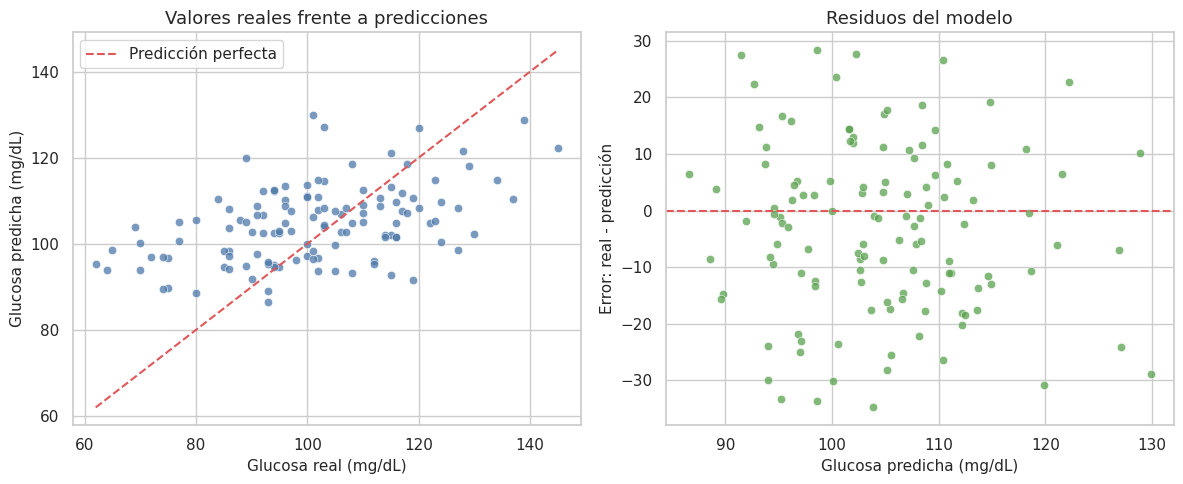

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(x=yr_test, y=pred_reg, ax=axes[0], color="#4C78A8", alpha=0.75)
limites = [min(yr_test.min(), pred_reg.min()), max(yr_test.max(), pred_reg.max())]
axes[0].plot(limites, limites, "--", color="#E15759", label="Predicción perfecta")
axes[0].set(
    title="Valores reales frente a predicciones",
    xlabel="Glucosa real (mg/dL)",
    ylabel="Glucosa predicha (mg/dL)",
)
axes[0].legend()

residuos = yr_test.to_numpy() - pred_reg
sns.scatterplot(x=pred_reg, y=residuos, ax=axes[1], color="#59A14F", alpha=0.75)
axes[1].axhline(0, linestyle="--", color="#E15759")
axes[1].set(
    title="Residuos del modelo",
    xlabel="Glucosa predicha (mg/dL)",
    ylabel="Error: real - predicción",
)

plt.tight_layout()
plt.show()


## Actividad 2. Interpretación de la regresión

1. Interpreta el MAE en las mismas unidades de la glucosa.
2. ¿Por qué el RMSE suele ser mayor que el MAE?
3. ¿Qué significa el valor obtenido de $R^2$?
4. ¿Los puntos se concentran cerca de la línea de predicción perfecta?
5. ¿Los residuos parecen aleatorios o muestran algún patrón?
6. Con base en las métricas, ¿usarías este modelo como modelo final? Justifica.

**Importante:** un resultado modesto también es un resultado válido. La evaluación sirve para reconocer las limitaciones del modelo y decidir qué mejorar.


### Respuestas – Actividad 2

Resultados obtenidos en prueba (123 registros): **MAE = 12,45 mg/dL**, **RMSE = 15,25 mg/dL**, **R² = 0,170**.

1. **MAE:** en promedio, la predicción se aleja de la glucosa real unos 12,4 mg/dL, hacia arriba o hacia abajo. Para dimensionarlo: la glucosa real del conjunto de prueba tiene una desviación estándar de 16,8 mg/dL, de modo que el modelo reduce poco el error que se tendría prediciendo siempre el promedio.
2. **RMSE > MAE:** el RMSE eleva cada error al cuadrado antes de promediar, así que los errores grandes pesan mucho más que los pequeños. Solo serían iguales si todos los errores tuvieran la misma magnitud. Aquí hay errores de hasta −34,8 y +28,4 mg/dL que empujan el RMSE (15,25) por encima del MAE (12,45).
3. **R² = 0,17:** el modelo explica alrededor del 17 % de la variabilidad de la glucosa en los datos de prueba; el 83 % restante no queda explicado por las variables usadas con una relación lineal. Es un ajuste débil.
4. **Línea de predicción perfecta:** no. La nube es ancha y casi horizontal: las predicciones se concentran entre 87 y 130 mg/dL aunque los valores reales van de 62 a 145. El modelo tiende a predecir cerca del promedio: sobrestima las glucosas bajas y subestima las altas.
5. **Residuos:** se distribuyen alrededor de cero sin forma de curva ni de embudo evidente (correlación entre predicción y residuo ≈ −0,07), así que no hay un patrón claro que indique una no linealidad fuerte. Sí se observa una dispersión grande (aprox. ±30 mg/dL) y un sesgo leve: el residuo medio es −3,4 mg/dL, es decir, el modelo sobrestima un poco en promedio, posiblemente por los valores extremos de glucosa que se conservaron en entrenamiento (máximo de 336 mg/dL).
6. **¿Modelo final?** No. Con R² = 0,17 y un error típico de 12–15 mg/dL, sus predicciones son apenas mejores que usar la media. Sirve como línea base. Antes de darlo por definitivo habría que tratar los outliers, probar transformaciones o modelos no lineales y, sobre todo, contar con variables más relacionadas con la glucosa; las disponibles (edad, IMC, presión, hábitos) la explican poco.

# 3. Bloque B: regresión logística para clasificación


## Pregunta de modelado

**¿Podemos predecir `Nivel_Riesgo` como Bajo, Medio o Alto?**

Aunque su nombre contiene la palabra *regresión*, la regresión logística se utiliza para clasificación. En este caso trabajaremos con tres clases.


In [9]:
objetivo_clas = "Nivel_Riesgo"

variables_clas = [
    "Edad",
    "Genero",
    "IMC",
    "Glucosa_mg_dL",
    "Presion_Sistolica_mmHg",
    "Colesterol_mg_dL",
    "Actividad_Fisica",
    "Fumador",
    "Horas_Sueno",
    "Nivel_Estres",
    "Consultas_Medicas",
    "Mes_Numero",
]

categoricas_clas = ["Genero", "Actividad_Fisica", "Fumador"]
numericas_clas = [columna for columna in variables_clas if columna not in categoricas_clas]

X_clas = df[variables_clas]
y_clas = df[objetivo_clas]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clas,
    y_clas,
    test_size=0.25,
    random_state=SEMILLA,
    stratify=y_clas,
)

print("Distribución en entrenamiento:")
print(yc_train.value_counts(normalize=True).round(3))
print("\nDistribución en prueba:")
print(yc_test.value_counts(normalize=True).round(3))


Distribución en entrenamiento:
Nivel_Riesgo
Medio    0.395
Bajo     0.339
Alto     0.266
Name: proportion, dtype: float64

Distribución en prueba:
Nivel_Riesgo
Medio    0.392
Bajo     0.344
Alto     0.264
Name: proportion, dtype: float64


In [10]:
def crear_preprocesador_clasificacion():
    return ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline(
                    steps=[
                        ("imputacion", SimpleImputer(strategy="median")),
                        ("escalamiento", StandardScaler()),
                    ]
                ),
                numericas_clas,
            ),
            (
                "cat",
                Pipeline(
                    steps=[
                        ("imputacion", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore")),
                    ]
                ),
                categoricas_clas,
            ),
        ]
    )


def calcular_metricas_clasificacion(y_real, y_pred):
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision_macro": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_real, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_real, y_pred, average="macro", zero_division=0),
    }


In [11]:
modelo_logistico = Pipeline(
    steps=[
        ("preprocesamiento", crear_preprocesador_clasificacion()),
        (
            "modelo",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=SEMILLA,
            ),
        ),
    ]
)

modelo_logistico.fit(Xc_train, yc_train)
pred_logistica = modelo_logistico.predict(Xc_test)

metricas_logistica = calcular_metricas_clasificacion(yc_test, pred_logistica)
pd.Series(metricas_logistica).round(3)


Accuracy           0.856
Precision_macro    0.858
Recall_macro       0.862
F1_macro           0.859
dtype: float64

## 3.1 Reporte de clasificación


In [12]:
reporte_logistica = pd.DataFrame(
    classification_report(
        yc_test,
        pred_logistica,
        labels=["Bajo", "Medio", "Alto"],
        output_dict=True,
        zero_division=0,
    )
).T

reporte_logistica.round(3)


,precision,recall,f1-score,support
Bajo,0.925,0.860,0.892,43.000
Medio,0.816,0.816,0.816,49.000
Alto,0.833,0.909,0.870,33.000
accuracy,0.856,0.856,0.856,0.856
macro avg,0.858,0.862,0.859,125.000
weighted avg,0.858,0.856,0.856,125.000


## 3.2 Matriz de confusión


En la matriz de confusión:

- las filas representan las clases reales;
- las columnas representan las clases predichas;
- la diagonal contiene las predicciones correctas;
- las celdas fuera de la diagonal muestran los tipos de error.


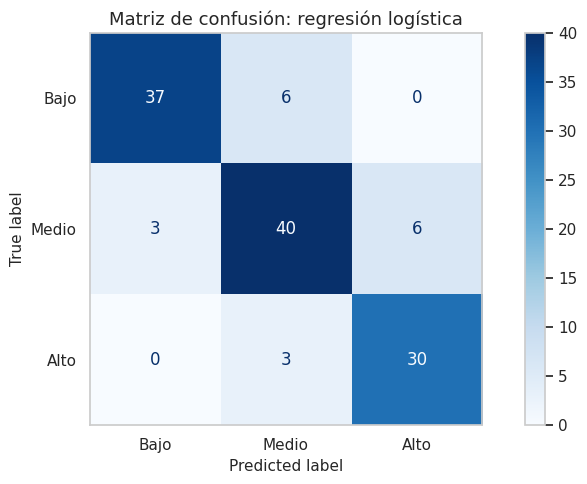

In [13]:
orden_clases = ["Bajo", "Medio", "Alto"]
matriz_logistica = confusion_matrix(yc_test, pred_logistica, labels=orden_clases)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_logistica,
    display_labels=orden_clases,
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión: regresión logística")
plt.grid(False)
plt.tight_layout()
plt.show()


## Actividad 3. Lectura de la matriz de confusión

1. ¿Cuántos registros fueron clasificados correctamente?
2. ¿Cuál clase tuvo el mayor recall?
3. ¿Qué confusión fue más frecuente: Bajo-Medio, Medio-Alto o Bajo-Alto?
4. ¿Por qué una clasificación equivocada entre categorías cercanas puede interpretarse de forma diferente a una confusión entre Bajo y Alto?
5. Explica con tus palabras la diferencia entre precision y recall.
6. ¿Qué aporta el F1-score frente a observar precision o recall por separado?


### Respuestas – Actividad 3

Matriz obtenida (filas = real, columnas = predicho):

| Real \ Predicho | Bajo | Medio | Alto |
|---|---|---|---|
| **Bajo** (43) | 37 | 6 | 0 |
| **Medio** (49) | 3 | 40 | 6 |
| **Alto** (33) | 0 | 3 | 30 |

1. **Aciertos:** 37 + 40 + 30 = **107 de 125** registros (accuracy = 0,856).
2. **Mayor recall:** la clase **Alto**, con 30/33 = 0,909 (Bajo: 0,860; Medio: 0,816).
3. **Confusión más frecuente:** **Bajo–Medio y Medio–Alto empatan con 9 casos cada una** (Bajo→Medio 6 + Medio→Bajo 3; Medio→Alto 6 + Alto→Medio 3). **Bajo–Alto tuvo 0 casos.** Todos los errores ocurren entre categorías vecinas.
4. **Categorías cercanas vs. extremas:** `Nivel_Riesgo` es ordinal. Confundir Bajo con Medio o Medio con Alto suele ocurrir con pacientes cercanos a la frontera entre niveles y el error es de un solo escalón. Confundir Bajo con Alto implica saltarse dos niveles: un paciente de riesgo alto tratado como bajo dejaría de recibir atención, y uno bajo tratado como alto generaría alarma y costos innecesarios. Por eso es un error más grave, y es buena señal que este modelo no lo cometa.
5. **Precision vs. recall:** la *precision* responde "de todos los que el modelo etiquetó como una clase, ¿cuántos lo eran realmente?" (qué tan confiable es la alarma). El *recall* responde "de todos los que realmente eran de esa clase, ¿cuántos encontró el modelo?" (qué tantos casos se le escapan). Ejemplo con Alto: precision = 30/36 = 0,833 (6 de los marcados como Alto eran Medio) y recall = 30/33 = 0,909 (se le escaparon 3 casos de Alto).
6. **F1-score:** es la media armónica de precision y recall, por lo que solo es alto cuando ambas lo son. Evita dejarse engañar por un modelo que logra un recall altísimo marcando casi todo como una clase (baja precision) o lo contrario, y resume el equilibrio en un solo número comparable entre modelos. Aquí el F1 macro es 0,859.

# 4. Bloque C: árbol de decisión


El árbol de decisión divide los datos mediante reglas sucesivas. Es fácil de explicar, admite relaciones no lineales y no necesita que las variables estén relacionadas de forma lineal. Sin control de profundidad puede memorizar el entrenamiento y sobreajustarse.


In [14]:
modelo_arbol = Pipeline(
    steps=[
        ("preprocesamiento", crear_preprocesador_clasificacion()),
        (
            "modelo",
            DecisionTreeClassifier(
                max_depth=5,
                min_samples_leaf=8,
                class_weight="balanced",
                random_state=SEMILLA,
            ),
        ),
    ]
)

modelo_arbol.fit(Xc_train, yc_train)
pred_arbol = modelo_arbol.predict(Xc_test)

metricas_arbol = calcular_metricas_clasificacion(yc_test, pred_arbol)
pd.Series(metricas_arbol).round(3)


Accuracy           0.680
Precision_macro    0.708
Recall_macro       0.674
F1_macro           0.685
dtype: float64

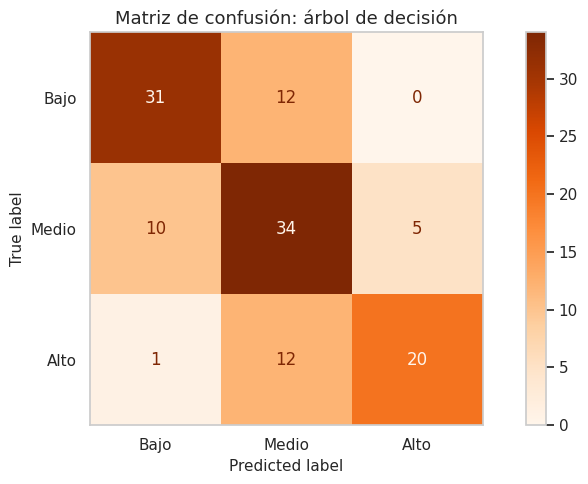

In [15]:
matriz_arbol = confusion_matrix(yc_test, pred_arbol, labels=orden_clases)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_arbol,
    display_labels=orden_clases,
)
disp.plot(cmap="Oranges", values_format="d")
plt.title("Matriz de confusión: árbol de decisión")
plt.grid(False)
plt.tight_layout()
plt.show()


## 4.1 Importancia de variables


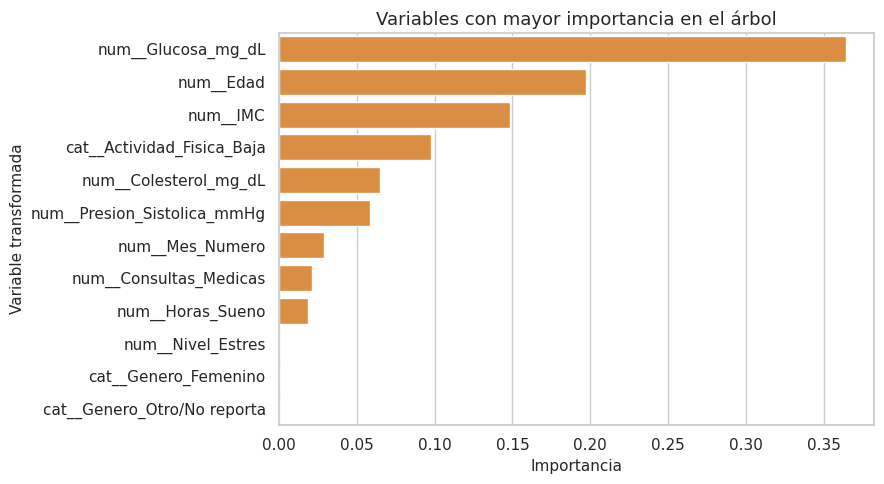

num__Glucosa_mg_dL             0.364
num__Edad                      0.197
num__IMC                       0.148
cat__Actividad_Fisica_Baja     0.098
num__Colesterol_mg_dL          0.065
num__Presion_Sistolica_mmHg    0.058
num__Mes_Numero                0.029
num__Consultas_Medicas         0.022
num__Horas_Sueno               0.019
num__Nivel_Estres              0.000
cat__Genero_Femenino           0.000
cat__Genero_Otro/No reporta    0.000
dtype: float64

In [16]:
preprocesador_entrenado = modelo_arbol.named_steps["preprocesamiento"]
arbol_entrenado = modelo_arbol.named_steps["modelo"]
nombres_variables = preprocesador_entrenado.get_feature_names_out()

importancias = (
    pd.Series(arbol_entrenado.feature_importances_, index=nombres_variables)
    .sort_values(ascending=False)
    .head(12)
)

ax = sns.barplot(x=importancias.values, y=importancias.index, color="#F28E2B")
ax.set(
    title="Variables con mayor importancia en el árbol",
    xlabel="Importancia",
    ylabel="Variable transformada",
)
plt.tight_layout()
plt.show()

importancias.round(3)


## 4.2 Visualización parcial del árbol


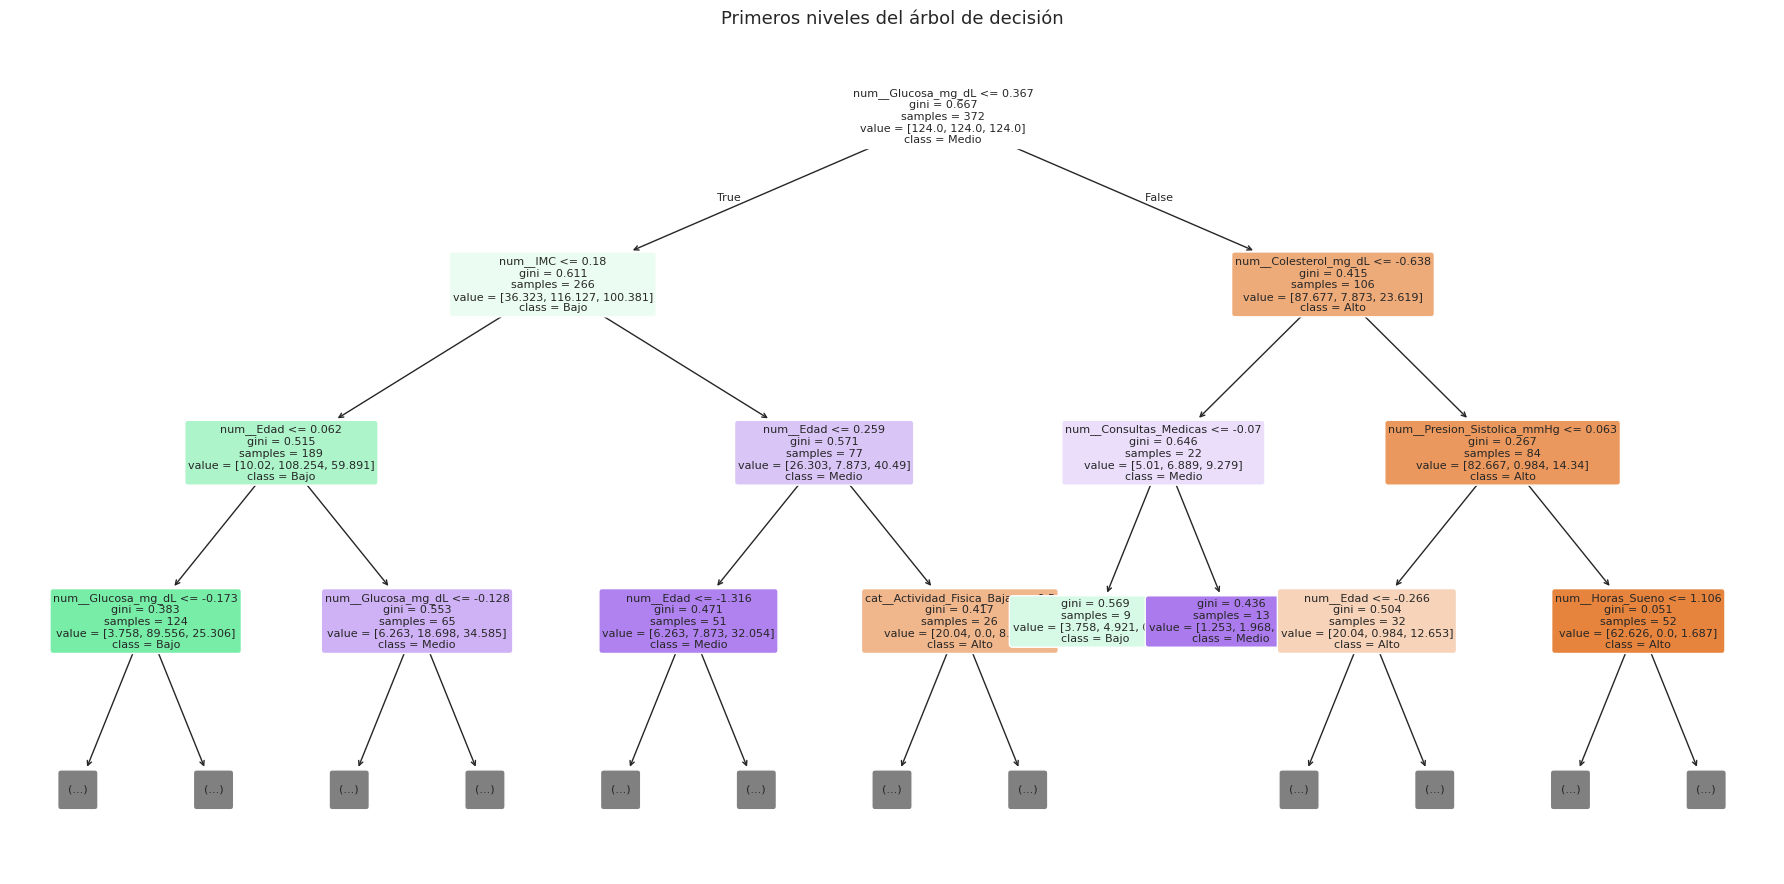

In [17]:
plt.figure(figsize=(18, 9))
plot_tree(
    arbol_entrenado,
    feature_names=nombres_variables,
    class_names=[str(clase) for clase in arbol_entrenado.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8,
)
plt.title("Primeros niveles del árbol de decisión")
plt.tight_layout()
plt.show()


La imagen muestra únicamente los primeros niveles para conservar la legibilidad. Sigue una ruta desde la raíz hasta una hoja y explica qué condiciones se aplican y cuál clase se predice.


## 4.3 Profundidad y sobreajuste


In [18]:
resultados_profundidad = []

for profundidad in [2, 3, 5, 8, None]:
    modelo_prueba = Pipeline(
        steps=[
            ("preprocesamiento", crear_preprocesador_clasificacion()),
            (
                "modelo",
                DecisionTreeClassifier(
                    max_depth=profundidad,
                    min_samples_leaf=4,
                    class_weight="balanced",
                    random_state=SEMILLA,
                ),
            ),
        ]
    )
    modelo_prueba.fit(Xc_train, yc_train)
    resultados_profundidad.append({
        "max_depth": "Sin límite" if profundidad is None else str(profundidad),
        "accuracy_train": modelo_prueba.score(Xc_train, yc_train),
        "accuracy_test": modelo_prueba.score(Xc_test, yc_test),
    })

tabla_profundidad = pd.DataFrame(resultados_profundidad)
tabla_profundidad.round(3)


,max_depth,accuracy_train,accuracy_test
0,2,0.632,0.624
1,3,0.718,0.656
2,5,0.839,0.688
3,8,0.884,0.624
4,Sin límite,0.882,0.640


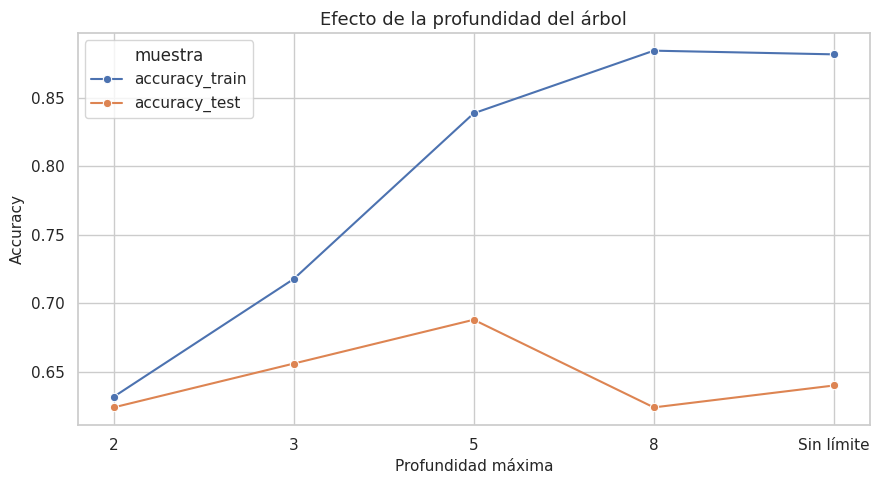

In [19]:
tabla_larga = tabla_profundidad.melt(
    id_vars="max_depth",
    value_vars=["accuracy_train", "accuracy_test"],
    var_name="muestra",
    value_name="accuracy",
)

ax = sns.lineplot(
    data=tabla_larga,
    x="max_depth",
    y="accuracy",
    hue="muestra",
    marker="o",
)
ax.set(
    title="Efecto de la profundidad del árbol",
    xlabel="Profundidad máxima",
    ylabel="Accuracy",
)
plt.tight_layout()
plt.show()


## Actividad 4. Interpretación del árbol

1. ¿Qué variables tuvieron mayor importancia?
2. ¿La importancia indica causalidad? Explica.
3. Compara las matrices de confusión del árbol y de la regresión logística.
4. ¿Qué ocurre con el accuracy de entrenamiento cuando aumenta la profundidad?
5. ¿En qué punto aparece una brecha importante entre entrenamiento y prueba?
6. ¿Qué profundidad elegirías y por qué?


### Respuestas – Actividad 4

**Ruta de ejemplo (sección 4.2).** Las variables numéricas aparecen estandarizadas en el árbol; entre paréntesis se da la equivalencia aproximada en unidades originales. Desde la raíz: `Glucosa > 0,37` (≈ más de 112,6 mg/dL) → `Colesterol > −0,64` (≈ más de 170 mg/dL) → `Presión sistólica > 0,06` (≈ más de 124 mmHg) → el árbol predice **Alto**. Es decir, glucosa, colesterol y presión simultáneamente elevados conducen a la clase de mayor riesgo.

1. **Variables más importantes:** Glucosa (0,364), Edad (0,197), IMC (0,148) y Actividad física baja (0,098). Luego Colesterol (0,065) y Presión sistólica (0,058). Nivel de estrés y género tuvieron importancia 0.
2. **¿Causalidad?** No. La importancia mide cuánto ayudó cada variable a reducir la impureza en las divisiones de *este* árbol con *estos* datos; es una medida de utilidad predictiva (asociación). Puede cambiar con otra semilla o profundidad, y se reparte de forma arbitraria entre variables correlacionadas. Además, aquí `Nivel_Riesgo` fue construido a partir de esas mismas variables, así que el árbol está recuperando la regla de construcción, no descubriendo causas.
3. **Comparación de matrices:**

| Real \ Predicho (árbol) | Bajo | Medio | Alto |
|---|---|---|---|
| **Bajo** | 31 | 12 | 0 |
| **Medio** | 10 | 34 | 5 |
| **Alto** | 1 | 12 | 20 |

   El árbol acierta 85 de 125 (0,680) frente a 107 de la logística (0,856). Empeora en las tres clases, sobre todo en **Alto**: su recall cae de 0,909 a 0,606 porque 12 casos de Alto se clasifican como Medio (la logística solo 3). Las confusiones Bajo–Medio suben de 9 a 22 y las Medio–Alto de 9 a 17. Además aparece un error grave que la logística no tenía: 1 paciente Alto clasificado como Bajo.
4. **Accuracy de entrenamiento:** aumenta con la profundidad: 0,632 (2) → 0,718 (3) → 0,839 (5) → 0,884 (8) y se estabiliza en 0,882 sin límite (no llega a 1 porque `min_samples_leaf=4` impide hojas de un solo caso). El árbol va memorizando cada vez más el entrenamiento.
5. **Brecha:** con profundidad 2 la diferencia es mínima (0,008) y con 3 es moderada (0,062). **A partir de profundidad 5 la brecha ya es importante (0,839 vs. 0,688 = 0,151)** y con 8 se dispara a 0,260, mientras el accuracy de prueba *baja* a 0,624. Eso es sobreajuste.
6. **Profundidad elegida:** **3**. Profundidad 5 tiene el accuracy de prueba más alto (0,688), pero la ventaja sobre 3 (0,656) equivale a solo 4 registros de 125 y viene acompañada de una brecha de 0,15 con entrenamiento. Con profundidad 3 el desempeño en prueba es prácticamente el mismo, la brecha es pequeña y el árbol es mucho más fácil de leer y explicar (máximo 8 reglas). Para confirmar la elección convendría usar validación cruzada en lugar de una sola partición.

# 5. Comparación de los modelos de clasificación


In [20]:
comparacion_clasificadores = pd.DataFrame(
    [
        {"Modelo": "Regresión logística", **metricas_logistica},
        {"Modelo": "Árbol de decisión", **metricas_arbol},
    ]
).set_index("Modelo")

comparacion_clasificadores.round(3)


,Accuracy,Precision_macro,Recall_macro,F1_macro
Modelo,,,,
Regresión logística,0.856,0.858,0.862,0.859
Árbol de decisión,0.680,0.708,0.674,0.685


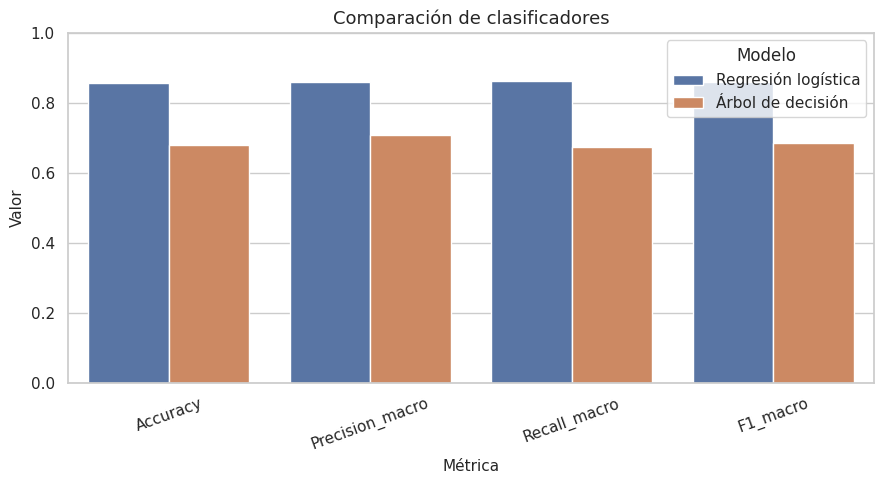

In [21]:
comparacion_larga = (
    comparacion_clasificadores.reset_index()
    .melt(id_vars="Modelo", var_name="Métrica", value_name="Valor")
)

ax = sns.barplot(data=comparacion_larga, x="Métrica", y="Valor", hue="Modelo")
ax.set(title="Comparación de clasificadores", xlabel="Métrica", ylabel="Valor")
ax.set_ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 5.1 Comprobación con validación cruzada


In [22]:
cv_logistica = cross_val_score(
    modelo_logistico,
    X_clas,
    y_clas,
    cv=5,
    scoring="f1_macro",
)

cv_arbol = cross_val_score(
    modelo_arbol,
    X_clas,
    y_clas,
    cv=5,
    scoring="f1_macro",
)

resumen_cv = pd.DataFrame({
    "Modelo": ["Regresión logística", "Árbol de decisión"],
    "F1_macro_promedio": [cv_logistica.mean(), cv_arbol.mean()],
    "Desviacion_estandar": [cv_logistica.std(), cv_arbol.std()],
})

resumen_cv.round(3)


,Modelo,F1_macro_promedio,Desviacion_estandar
0,Regresión logística,0.837,0.044
1,Árbol de decisión,0.640,0.037


## Actividad 5. Selección del clasificador

Redacta una recomendación de 120 a 180 palabras que responda:

- ¿Cuál modelo obtuvo mejores métricas en prueba?
- ¿La validación cruzada respalda la misma conclusión?
- ¿Cuál es más fácil de interpretar?
- ¿Qué errores aparecen en cada matriz de confusión?
- ¿Qué modelo elegirías para continuar y qué mejorarías antes de utilizarlo?

No elijas un modelo únicamente por el accuracy. Utiliza al menos tres evidencias.


### Respuesta – Actividad 5: recomendación

Recomendamos continuar con la **regresión logística**. En prueba superó al árbol en todas las métricas: accuracy 0,856 frente a 0,680 y F1 macro 0,859 frente a 0,685. La validación cruzada de cinco particiones respalda la misma conclusión: F1 macro promedio de 0,837 (±0,044) contra 0,640 (±0,037); incluso la peor partición de la logística (0,796) supera a la mejor del árbol (0,673), así que la diferencia no depende de una división afortunada. Las matrices de confusión muestran que la logística solo se equivoca entre niveles vecinos (18 errores, ninguno Bajo–Alto), mientras el árbol comete 40 errores, deja pasar 12 casos de Alto como Medio (recall de Alto 0,61 frente a 0,91) y clasifica un Alto como Bajo. El árbol es más fácil de interpretar porque produce reglas legibles, pero esa ventaja no compensa su menor desempeño; además, los coeficientes de la logística también pueden explicarse. Antes de utilizarla revisaríamos los valores extremos, ajustaríamos la regularización y los umbrales para proteger el recall de Alto, y la validaríamos con datos reales.

# 6. Bloque D: clustering con K-means


## Pregunta de modelado

**¿Existen grupos de pacientes con perfiles similares sin utilizar `Nivel_Riesgo` como respuesta?**

K-means es un modelo no supervisado. Durante su entrenamiento no conoce las etiquetas Bajo, Medio o Alto. Utilizaremos únicamente variables numéricas estandarizadas.


In [23]:
variables_cluster = [
    "Edad",
    "IMC",
    "Glucosa_mg_dL",
    "Presion_Sistolica_mmHg",
    "Colesterol_mg_dL",
    "Horas_Sueno",
    "Nivel_Estres",
    "Consultas_Medicas",
]

preprocesador_cluster = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="median")),
        ("escalamiento", StandardScaler()),
    ]
)

X_cluster = preprocesador_cluster.fit_transform(df[variables_cluster])
print("Matriz para clustering:", X_cluster.shape)


Matriz para clustering: (497, 8)


## 6.1 Selección del número de clusters


In [24]:
resultados_k = []

for k in range(2, 7):
    modelo_k = KMeans(n_clusters=k, random_state=SEMILLA, n_init=20)
    etiquetas_k = modelo_k.fit_predict(X_cluster)
    resultados_k.append({
        "k": k,
        "inercia": modelo_k.inertia_,
        "silhouette": silhouette_score(X_cluster, etiquetas_k),
    })

tabla_k = pd.DataFrame(resultados_k)
tabla_k.round(3)


,k,inercia,silhouette
0,2,3233.402,0.182
1,3,2943.905,0.132
2,4,2677.846,0.145
3,5,2488.346,0.127
4,6,2348.753,0.118


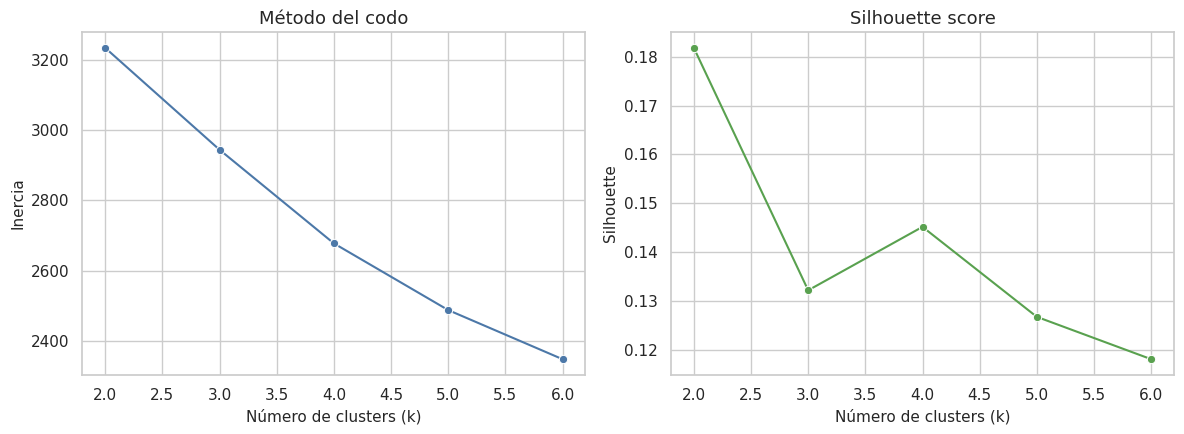

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.lineplot(data=tabla_k, x="k", y="inercia", marker="o", ax=axes[0], color="#4C78A8")
axes[0].set(title="Método del codo", xlabel="Número de clusters (k)", ylabel="Inercia")

sns.lineplot(data=tabla_k, x="k", y="silhouette", marker="o", ax=axes[1], color="#59A14F")
axes[1].set(title="Silhouette score", xlabel="Número de clusters (k)", ylabel="Silhouette")

plt.tight_layout()
plt.show()


## Actividad 6. Elección de $k$

1. ¿Dónde observas el cambio más importante en la curva de inercia?
2. ¿Qué valor de $k$ tiene el mayor silhouette score?
3. ¿Las dos evidencias sugieren la misma solución?
4. ¿Qué indica un silhouette cercano a 1, a 0 o menor que 0?
5. Selecciona un valor de $k$ y justifica tu decisión.

La siguiente celda elige automáticamente el mayor silhouette para continuar. Puedes reemplazar `k_seleccionado` por otro valor si tu argumento lo justifica.


### Respuestas – Actividad 6

| k | Inercia | Silhouette |
|---|---|---|
| 2 | 3233,4 | 0,182 |
| 3 | 2943,9 | 0,132 |
| 4 | 2677,8 | 0,145 |
| 5 | 2488,3 | 0,127 |
| 6 | 2348,8 | 0,118 |

1. **Curva de inercia:** no hay un codo marcado. Las caídas son similares y van disminuyendo poco a poco: −289 (de 2 a 3), −266 (de 3 a 4), −190 (de 4 a 5) y −140 (de 5 a 6). El cambio de ritmo más visible está después de **k = 4**, donde la reducción empieza a ser claramente menor.
2. **Mayor silhouette:** **k = 2**, con 0,182. El segundo mejor es k = 4 (0,145).
3. **¿Coinciden?** No del todo. El silhouette favorece k = 2, mientras que el codo, que es débil, apuntaría hacia k = 4. Que ninguna de las dos evidencias sea contundente indica que los datos no tienen grupos claramente separados.
4. **Interpretación del silhouette:** cerca de **1**, los puntos están muy próximos a su propio cluster y lejos de los demás (grupos compactos y bien separados). Cerca de **0**, los puntos están en la frontera entre clusters, que se solapan. **Menor que 0**, el punto está, en promedio, más cerca de otro cluster que del suyo: probablemente quedó mal asignado.
5. **k elegido: 2.** Es el valor con mayor silhouette, la inercia no ofrece un codo claro que justifique más grupos y dos perfiles son más fáciles de describir y más estables con 497 registros. Reconocemos que 0,182 es un valor bajo: la solución describe una tendencia general más que dos grupos nítidos. k = 4 sería una alternativa razonable si se quisiera más detalle.

In [26]:
# Se mantiene k = 2 (mayor silhouette), según la justificación de la Actividad 6.
k_seleccionado = int(tabla_k.loc[tabla_k["silhouette"].idxmax(), "k"])
print("k seleccionado:", k_seleccionado)

modelo_kmeans = KMeans(
    n_clusters=k_seleccionado,
    random_state=SEMILLA,
    n_init=20,
)

df["Cluster"] = modelo_kmeans.fit_predict(X_cluster)
df["Cluster"].value_counts().sort_index()


k seleccionado: 2


Cluster
0    221
1    276
Name: count, dtype: int64

## 6.2 Perfil de los clusters


In [27]:
perfil_clusters = df.groupby("Cluster")[variables_cluster].mean().round(2)
perfil_clusters


,Edad,IMC,Glucosa_mg_dL,Presion_Sistolica_mmHg,Colesterol_mg_dL,Horas_Sueno,Nivel_Estres,Consultas_Medicas
Cluster,,,,,,,,
0,58.85,29.37,114.21,131.76,208.00,7.04,5.59,3.44
1,38.58,25.46,97.18,116.48,173.81,6.97,5.56,1.99


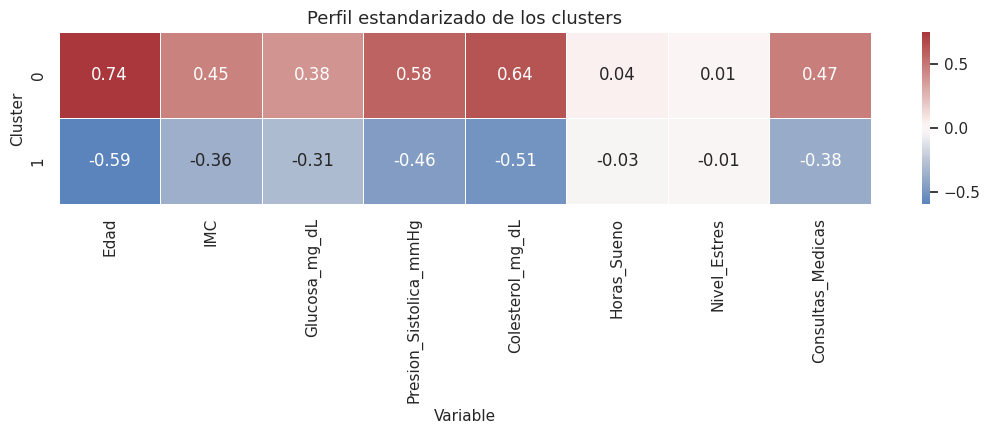

In [28]:
perfil_estandarizado = pd.DataFrame(
    X_cluster,
    columns=variables_cluster,
    index=df.index,
)
perfil_estandarizado["Cluster"] = df["Cluster"]
perfil_estandarizado = perfil_estandarizado.groupby("Cluster").mean()

plt.figure(figsize=(11, 4.5))
sns.heatmap(
    perfil_estandarizado,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    linewidths=0.5,
)
plt.title("Perfil estandarizado de los clusters")
plt.xlabel("Variable")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()


## 6.3 Visualización de los clusters con PCA


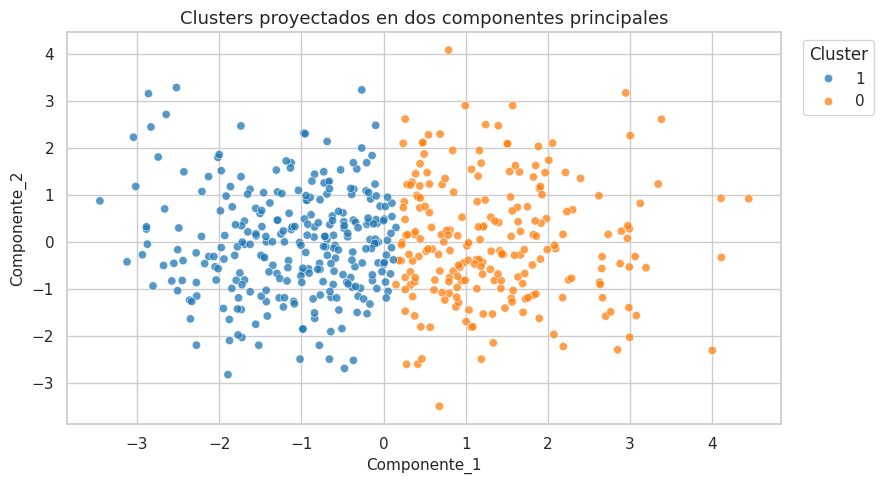

Varianza explicada por las dos componentes: 0.454


In [29]:
pca = PCA(n_components=2, random_state=SEMILLA)
componentes = pca.fit_transform(X_cluster)

df_pca = pd.DataFrame({
    "Componente_1": componentes[:, 0],
    "Componente_2": componentes[:, 1],
    "Cluster": df["Cluster"].astype(str),
    "Nivel_Riesgo": df["Nivel_Riesgo"],
})

ax = sns.scatterplot(
    data=df_pca,
    x="Componente_1",
    y="Componente_2",
    hue="Cluster",
    palette="tab10",
    alpha=0.75,
)
ax.set(title="Clusters proyectados en dos componentes principales")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Varianza explicada por las dos componentes:", round(pca.explained_variance_ratio_.sum(), 3))


## 6.4 Comparación exploratoria con el nivel de riesgo


Esta comparación se realiza **después** del clustering. `Nivel_Riesgo` no participó en el entrenamiento. La tabla sirve para interpretar si los grupos descubiertos tienen alguna relación con la etiqueta disponible; no convierte el clustering en clasificación.


In [30]:
clusters_vs_riesgo = pd.crosstab(
    df["Cluster"],
    df["Nivel_Riesgo"],
    normalize="index",
).reindex(columns=["Bajo", "Medio", "Alto"]) * 100

clusters_vs_riesgo.round(1)


Nivel_Riesgo,Bajo,Medio,Alto
Cluster,,,
0,5.9,39.4,54.8
1,56.5,39.5,4.0


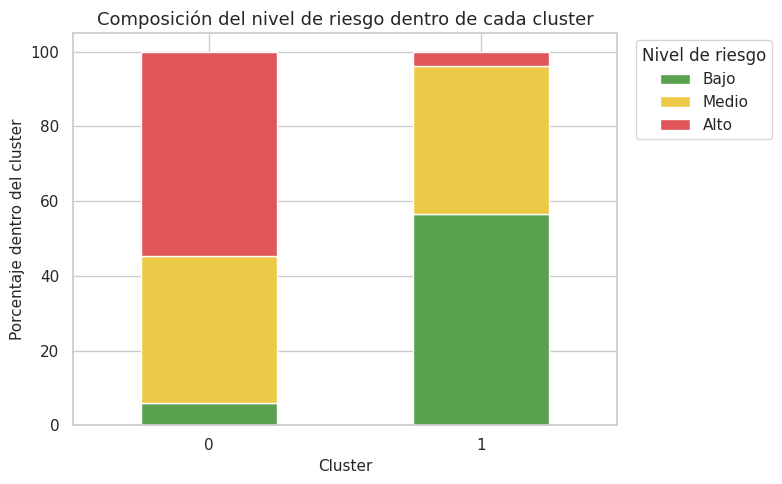

In [31]:
ax = clusters_vs_riesgo.plot(
    kind="bar",
    stacked=True,
    color=["#59A14F", "#EDC948", "#E15759"],
    figsize=(8, 5),
)
ax.set(
    title="Composición del nivel de riesgo dentro de cada cluster",
    xlabel="Cluster",
    ylabel="Porcentaje dentro del cluster",
)
ax.legend(title="Nivel de riesgo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Actividad 7. Interpretación del clustering

1. Describe cada cluster utilizando al menos cuatro variables del perfil.
2. Propón un nombre descriptivo para cada grupo. Evita nombres clínicos que el dataset no permite justificar.
3. ¿Los clusters aparecen completamente separados en la proyección PCA?
4. ¿Qué porcentaje de la variación representan las dos componentes mostradas?
5. ¿Cómo se relaciona cada cluster con `Nivel_Riesgo`?
6. ¿Por qué no tendría sentido evaluar K-means con accuracy y una matriz de confusión como si fuera un clasificador?
7. ¿Qué limitaciones observas en el silhouette score obtenido?


### Respuestas – Actividad 7

1. **Descripción de los clusters (promedios):**
   - **Cluster 0 (221 personas):** edad 58,9 años, IMC 29,4, glucosa 114,2 mg/dL, presión sistólica 131,8 mmHg, colesterol 208,0 mg/dL y 3,4 consultas médicas. Todas estas variables están por encima del promedio general (entre +0,4 y +0,7 desviaciones estándar).
   - **Cluster 1 (276 personas):** edad 38,6 años, IMC 25,5, glucosa 97,2 mg/dL, presión sistólica 116,5 mmHg, colesterol 173,8 mg/dL y 2,0 consultas médicas. Todas por debajo del promedio general.
   - Las **horas de sueño** (7,04 vs. 6,97) y el **nivel de estrés** (5,59 vs. 5,56) son prácticamente iguales en ambos grupos: no ayudan a diferenciarlos.
2. **Nombres propuestos:** Cluster 0 → **"Mayor edad, indicadores más altos y más consultas"**; Cluster 1 → **"Más jóvenes, indicadores más bajos y menos consultas"**. Evitamos términos como "diabéticos" o "hipertensos" porque el dataset no contiene diagnósticos.
3. **Separación en PCA:** no. Los dos grupos ocupan lados opuestos sobre la primera componente, pero forman una sola nube continua con una zona de contacto amplia en el centro; no hay un espacio vacío entre ellos.
4. **Varianza representada:** las dos componentes explican el **45,4 %** de la variación (27,8 % + 17,6 %). Más de la mitad de la información no se ve en el gráfico, así que parte del solapamiento o de la separación puede ser un efecto de la proyección.
5. **Relación con `Nivel_Riesgo`:**

| Cluster | Bajo | Medio | Alto |
|---|---|---|---|
| 0 | 5,9 % | 39,4 % | 54,8 % |
| 1 | 56,5 % | 39,5 % | 4,0 % |

   El cluster 0 concentra el riesgo Alto (121 de los 132 casos de Alto están allí) y el cluster 1 concentra el riesgo Bajo (156 de 169). La clase **Medio se reparte casi por igual** (≈39 % en ambos), lo que es coherente con que sea la categoría intermedia. Hay relación, pero no equivalencia: dos grupos no pueden reproducir tres niveles.
6. **¿Por qué no accuracy ni matriz de confusión?** Porque K-means no tiene una respuesta correcta contra la cual compararse: no predice `Nivel_Riesgo`, sino que agrupa por similitud. Los números de cluster (0, 1) son arbitrarios y podrían intercambiarse, el número de grupos (2) ni siquiera coincide con el de clases (3), y los grupos pueden reflejar una estructura distinta e igualmente válida. Se evalúa con medidas internas (inercia, silhouette) y con la utilidad de los perfiles.
7. **Limitaciones del silhouette:** el valor de 0,182 es bajo, cercano a 0, lo que indica clusters muy solapados; cerca del 8 % de los registros tiene silhouette negativo y el cluster 0 es bastante más difuso (0,11) que el cluster 1 (0,24). La diferencia entre valores de k es pequeña (0,12 a 0,18), así que la elección de k es poco firme. Además, el silhouette favorece grupos esféricos y de tamaño parecido, usa distancias euclidianas que son sensibles a los outliers que conservamos, e incluye dos variables (sueño y estrés) que no discriminan y añaden ruido.

# 7. Síntesis: ¿cuándo conviene cada modelo?


Completa la siguiente tabla en una celda de texto:

| Modelo | Tipo de tarea | Variable objetivo | Cuándo conviene | Métricas utilizadas | Limitación observada |
|---|---|---|---|---|---|
| Regresión lineal | | | | | |
| Regresión logística | | | | | |
| Árbol de decisión | | | | | |
| K-means | | | | | |


### Tabla de síntesis

| Modelo | Tipo de tarea | Variable objetivo | Cuándo conviene | Métricas utilizadas | Limitación observada |
|---|---|---|---|---|---|
| Regresión lineal | Supervisada: regresión | `Glucosa_mg_dL` (numérica continua) | Cuando se quiere estimar una cantidad y la relación con los predictores es aproximadamente lineal; como línea base interpretable | MAE = 12,45 mg/dL, RMSE = 15,25 mg/dL, R² = 0,170 | Explica solo el 17 % de la variabilidad; predice cerca de la media y falla en los valores bajos y altos; sensible a outliers |
| Regresión logística | Supervisada: clasificación | `Nivel_Riesgo` (Bajo, Medio, Alto) | Cuando se quiere predecir una categoría y las clases se separan con fronteras aproximadamente lineales; da probabilidades y coeficientes interpretables | Accuracy = 0,856; precision macro = 0,858; recall macro = 0,862; F1 macro = 0,859; matriz de confusión; F1 en validación cruzada = 0,837 | 18 errores, todos entre clases vecinas; la clase Medio es la más difícil (recall 0,816); requiere escalar y codificar variables |
| Árbol de decisión | Supervisada: clasificación | `Nivel_Riesgo` (Bajo, Medio, Alto) | Cuando se necesitan reglas explícitas y fáciles de comunicar, o hay relaciones no lineales e interacciones | Accuracy = 0,680; precision macro = 0,708; recall macro = 0,674; F1 macro = 0,685; matriz de confusión; F1 en validación cruzada = 0,640 | Se sobreajusta al aumentar la profundidad (0,884 en entrenamiento vs. 0,624 en prueba con profundidad 8); recall de Alto de solo 0,61 |
| K-means | No supervisada: clustering | Ninguna (`Nivel_Riesgo` solo se usa después para interpretar) | Cuando no hay etiquetas y se quieren explorar perfiles o segmentos con variables numéricas escaladas | Inercia (3233,4 con k = 2), silhouette = 0,182, perfil de clusters | Grupos muy solapados (silhouette bajo); hay que elegir k; solo dos perfiles generales; sensible a escala y outliers |

# 8. Conclusión de la actividad


Redacta una conclusión de 180 a 250 palabras que responda:

- ¿Qué diferencia práctica encontraste entre regresión, clasificación y clustering?
- ¿Qué modelo supervisado funcionó mejor y con qué evidencia?
- ¿Qué aprendiste al interpretar una matriz de confusión?
- ¿Qué aportó el análisis de clusters que no mostraban los modelos supervisados?
- ¿Qué mejorarías en los datos o en los modelos antes de una siguiente fase?

La conclusión debe apoyarse en las métricas obtenidas, no únicamente en opiniones generales.


### Conclusión

La diferencia práctica entre las tres tareas está en la pregunta y en cómo se evalúa la respuesta. La regresión estima una cantidad (glucosa) y se mide con errores en sus mismas unidades; la clasificación asigna una categoría (nivel de riesgo) y se mide contando aciertos y tipos de error; el clustering no tiene respuesta correcta y solo propone grupos que debemos interpretar.

El modelo supervisado que mejor funcionó fue la regresión logística: accuracy de 0,856 y F1 macro de 0,859 en prueba, confirmado por la validación cruzada (0,837), frente a 0,680 y 0,685 del árbol de decisión. La regresión lineal, en cambio, apenas explicó el 17 % de la variabilidad de la glucosa (MAE de 12,4 mg/dL), un resultado modesto pero útil para reconocer sus límites.

La matriz de confusión nos enseñó que el accuracy no cuenta toda la historia: importa qué errores se cometen. La logística solo confundió niveles vecinos, mientras el árbol dejó pasar 12 casos de riesgo Alto como Medio.

El clustering aportó una mirada distinta: sin usar la etiqueta encontró dos perfiles generales, diferenciados por edad, IMC, presión, colesterol y consultas, y mostró que sueño y estrés casi no distinguen a los pacientes. Sin embargo, el silhouette de 0,182 indica grupos muy solapados.

Para una siguiente fase trataríamos los valores extremos, ajustaríamos hiperparámetros con validación cruzada, probaríamos modelos de ensamble y validaríamos con datos reales, pues este dataset es sintético.

## Exportación a Streamlit
Se conserva la regresión logística y la separación original. Para el informe de la aplicación, se calcula además una validación cruzada solo en el conjunto de entrenamiento. El pipeline serializado incluye imputación, escalado, codificación y clasificador.

In [ ]:
import json

import joblib

clases = ["Bajo", "Medio", "Alto"]
campos = {}
for nombre in variables_clas:
    columna = Xc_train[nombre].dropna()
    if nombre in categoricas_clas or nombre == "Mes_Numero":
        campos[nombre] = {"options": sorted(columna.unique().tolist())}
        continue
    entero = bool((columna % 1 == 0).all())
    convertir = int if entero else float
    campos[nombre] = {
        "min": convertir(columna.min()),
        "max": convertir(columna.max()),
        "default": convertir(round(columna.median(), 2)),
        "integer": entero,
    }

cv_entrenamiento = cross_val_score(
    modelo_logistico, Xc_train, yc_train, cv=5, scoring="f1_macro"
)
reporte = classification_report(
    yc_test, pred_logistica, labels=clases, output_dict=True, zero_division=0
)
actividad = pd.crosstab(df["Actividad_Fisica"], df[objetivo_clas], normalize="index")
actividad = actividad.reindex(index=["Baja", "Moderada", "Alta"], columns=clases)
resultado = {
    "classes": clases,
    "fields": campos,
    "test_count": len(yc_test),
    "metrics": metricas_logistica,
    "cv_mean": cv_entrenamiento.mean(),
    "cv_std": cv_entrenamiento.std(),
    "class_metrics": {clase: reporte[clase] for clase in clases},
    "matrix": confusion_matrix(yc_test, pred_logistica, labels=clases).tolist(),
    "distribution": df[objetivo_clas].value_counts().reindex(clases).to_dict(),
    "glucose": df.groupby(objetivo_clas)["Glucosa_mg_dL"].median().reindex(clases).to_dict(),
    "activity": actividad.mul(100).round(1).to_dict(orient="index"),
}
joblib.dump(modelo_logistico, "pipeline.joblib", compress=3)
Path("resultados.json").write_text(
    json.dumps(resultado, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8"
)
print(f"F1 macro de prueba: {metricas_logistica['F1_macro']:.3f}")
print(f"F1 macro en CV de entrenamiento: {cv_entrenamiento.mean():.3f} ± {cv_entrenamiento.std():.3f}")


F1 macro de prueba: 0.859
F1 macro en CV de entrenamiento: 0.842 ± 0.030
